In [1]:
import os

import ipywidgets as widgets

from track_model import (
    plot_training_progress,
    plot_population_returns,
    extract_run_info,
    format_run_summary,
    plot_sweep_trajectories,
    plot_sweep_timeseries,
    plot_sweep_final_distance,
    plot_reward_weight_schedule,
)

Plotting combined training progress for ['2026-11-06_10-38-56_12', '2026-11-06_16-56-27_14']...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-05_19-01-48_27...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-09_19-58-51_29...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-09_23-50-44_18...


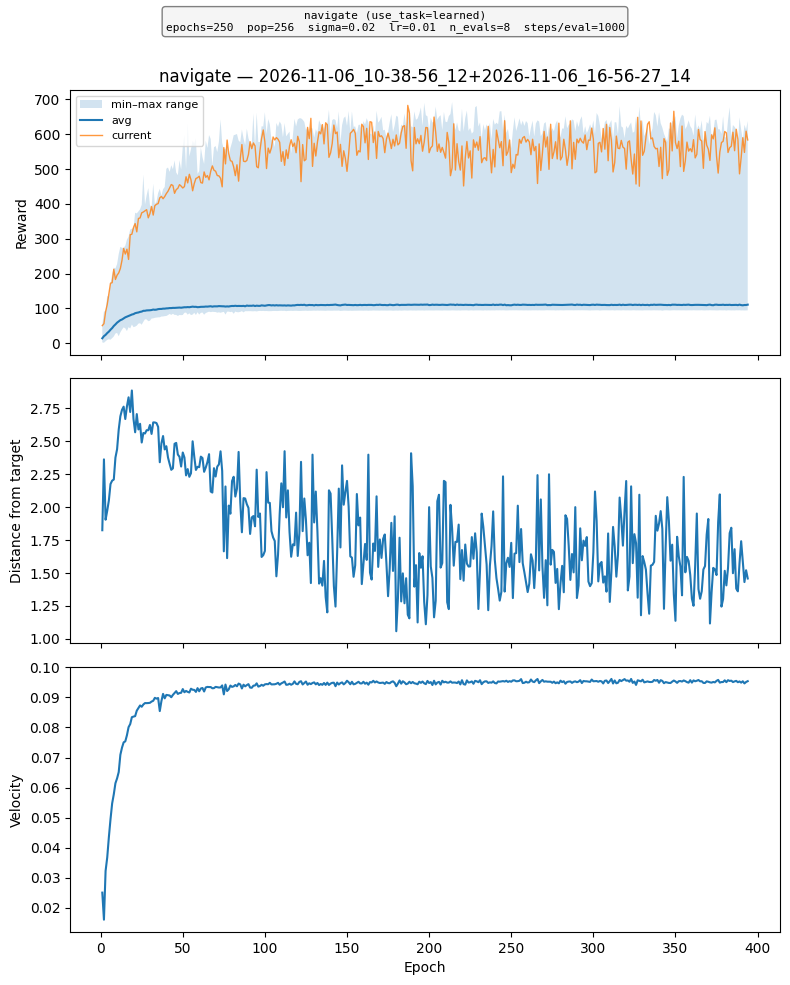

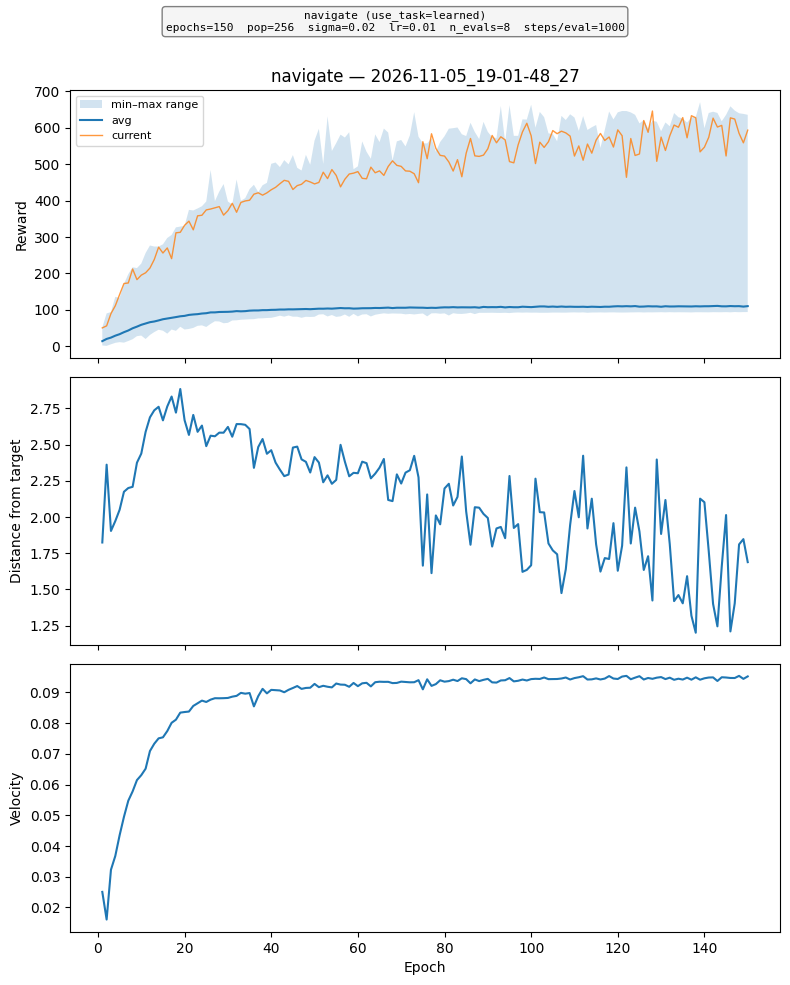

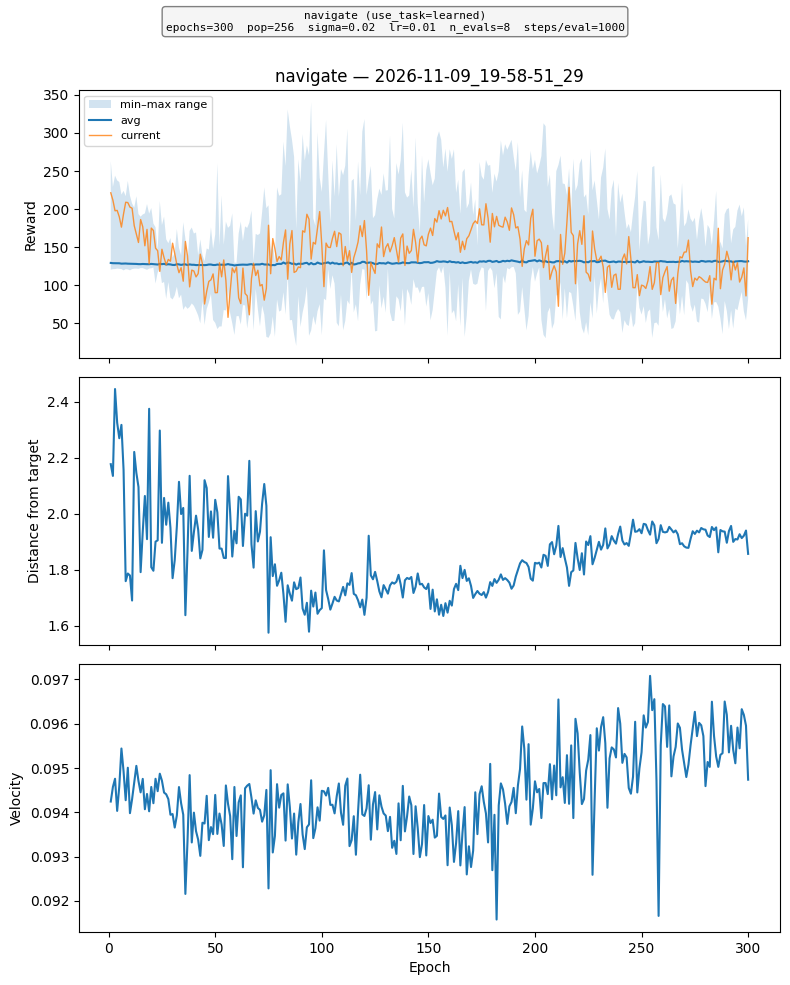

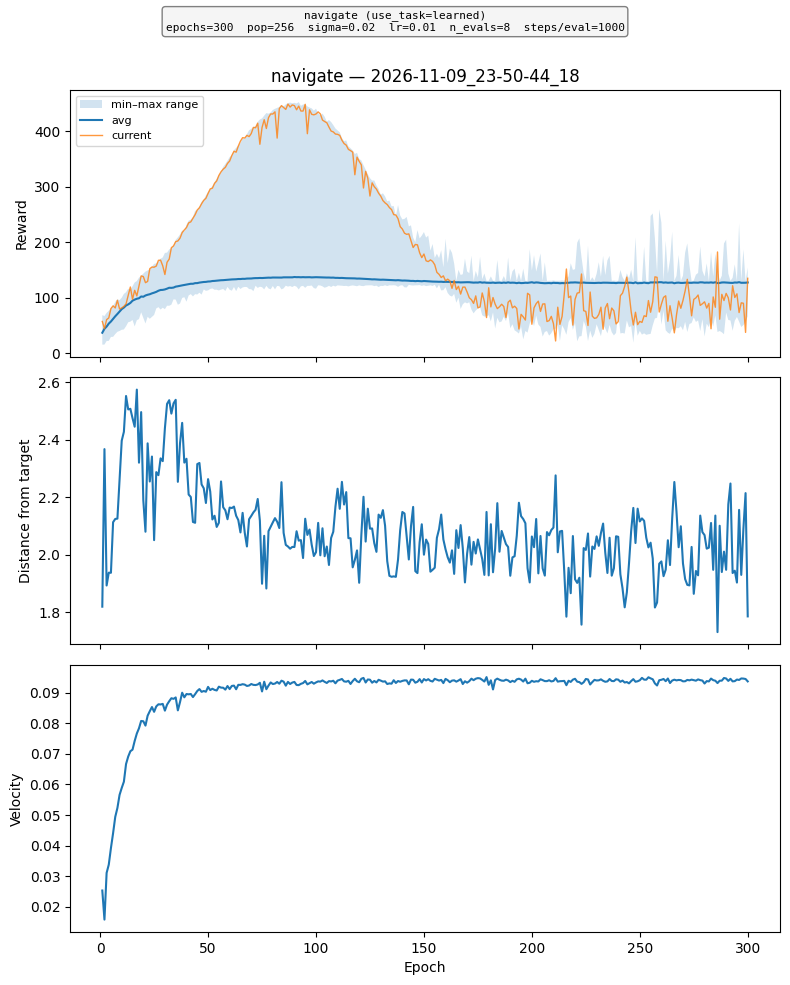

In [2]:
dir = r"D:\ncap-swimmer\FromGPUSERVER"

# 2026-11-05_19-01-48_27 and 2026-11-06_16-56-27_14 are the same training
# session (the second is a warm-started continuation of the first), so
# combine them into one continuous plot. 2026-11-09_19-58-51_29 is a
# separate, standalone run.
combined_runs = ["2026-11-06_10-38-56_12", "2026-11-06_16-56-27_14"]
solo_runs = ["2026-11-05_19-01-48_27", "2026-11-09_19-58-51_29", "2026-11-09_23-50-44_18"]

combined_csvs = [os.path.join(dir, name, "progress.csv") for name in combined_runs]
try:
    run_info = extract_run_info(os.path.join(dir, combined_runs[-1]))
except Exception as e:
    print(f"Failed to extract run info from {combined_runs[-1]}: {e}")
    run_info = None
print(f"Plotting combined training progress for {combined_runs}...")
plot_training_progress(combined_csvs, run_info=run_info, save=True, save_dir=r"D:\ncap-swimmer")

for name in solo_runs:
    run_dir = os.path.join(dir, name)
    csv_path = os.path.join(run_dir, "progress.csv")
    try:
        run_info = extract_run_info(run_dir)
    except Exception as e:
        print(f"Failed to extract run info from {run_dir}: {e}")
        run_info = None
    print(f"Plotting training progress for {run_dir}...")
    plot_training_progress(csv_path, run_info=run_info, save=True, save_dir=r"D:\ncap-swimmer")

In [ ]:
sweep_csv = os.path.join(r"D:\ncap-swimmer\outputs\<run>", "sweep_results.csv")

plot_sweep_trajectories(sweep_csv, save=True, save_dir=r"D:\ncap-swimmer")
plot_sweep_timeseries(sweep_csv, save=True, save_dir=r"D:\ncap-swimmer")
plot_sweep_final_distance(sweep_csv, save=True, save_dir=r"D:\ncap-swimmer")  # navigate sweeps only

In [2]:
widgets.interact(
    plot_reward_weight_schedule,
    n_epochs=widgets.IntSlider(min=50, max=600, step=10, value=300, description='n_epochs'),
    speed_tau=widgets.IntSlider(min=5, max=150, step=5, value=40, description='speed_tau'),
    dir_width=widgets.IntSlider(min=5, max=150, step=5, value=40, description='dir_width'),
    dist_start_epoch=widgets.IntSlider(min=0, max=600, step=10, value=160, description='dist_start_epoch'),
    dist_tau=widgets.IntSlider(min=5, max=150, step=5, value=60, description='dist_tau'),
    temperature=widgets.FloatSlider(min=0.1, max=2.0, step=0.1, value=0.5, description='temperature'),
);

interactive(children=(IntSlider(value=300, description='n_epochs', max=600, min=50, step=10), IntSlider(value=…